# Task 4: Training Performance Analysis

Training and validation metrics over the original 10 epochs.


## 1. Load Training History


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

history_path = Path("training_history.json")

with open(history_path, "r") as f:
    history = json.load(f)

print("Available metrics:", history.keys())
print("Number of epochs:", len(history["train_loss"]))

Available metrics: dict_keys(['train_loss', 'train_acc', 'val_loss', 'val_acc'])
Number of epochs: 10


## 2. Training Results Table


In [2]:
epochs = list(range(1, len(history["train_loss"]) + 1))

results = pd.DataFrame({
    "Epoch": epochs,
    "Training Loss": history["train_loss"],
    "Training Accuracy (%)": [x * 100 for x in history["train_acc"]],
    "Validation Loss": history["val_loss"],
    "Validation Accuracy (%)": [x * 100 for x in history["val_acc"]]
})

display(results.round(4))

,Epoch,Training Loss,Training Accuracy (%),Validation Loss,Validation Accuracy (%)
0,1,0.2725,92.2893,0.1929,93.7544
1,2,0.1324,95.6634,0.1524,94.9250
2,3,0.1155,96.0661,0.1407,95.0507
3,4,0.1070,96.3037,0.1255,95.7263
4,5,0.1009,96.4903,0.1276,95.5142
5,6,0.0980,96.5590,0.1444,95.1214
6,7,0.0965,96.6592,0.1160,95.9384
7,8,0.0937,96.6376,0.1221,95.8520
8,9,0.0893,96.8222,0.1195,95.8520
9,10,0.0914,96.7790,0.1189,95.9777


## 3.1 Training and Validation Accuracy


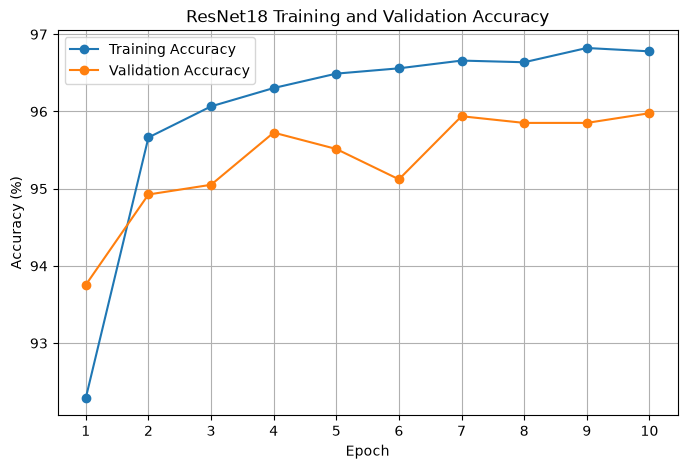

In [3]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, results["Training Accuracy (%)"],
         marker="o", label="Training Accuracy")

plt.plot(epochs, results["Validation Accuracy (%)"],
         marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet18 Training and Validation Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

## 3.2 Training and Validation Loss


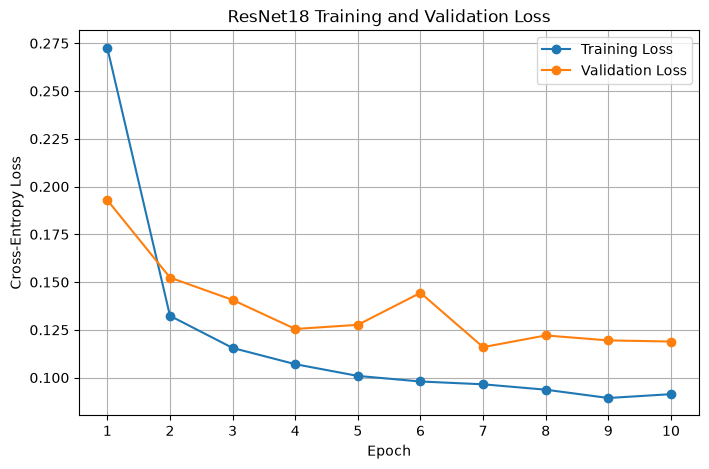

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"],
         marker="o", label="Training Loss")

plt.plot(epochs, history["val_loss"],
         marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ResNet18 Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

## 4. Training–Validation Accuracy Gap


In [6]:
final_train_acc = results["Training Accuracy (%)"].iloc[-1]
final_val_acc = results["Validation Accuracy (%)"].iloc[-1]

accuracy_gap = final_train_acc - final_val_acc

best_epoch = results.loc[
    results["Validation Accuracy (%)"].idxmax(), "Epoch"
]

print(f"Final training accuracy: {final_train_acc:.2f}%")
print(f"Final validation accuracy: {final_val_acc:.2f}%")
print(f"Accuracy gap: {accuracy_gap:.2f} percentage points")
print(f"Best validation epoch: {best_epoch}")

Final training accuracy: 96.78%
Final validation accuracy: 95.98%
Accuracy gap: 0.80 percentage points
Best validation epoch: 10
